# chromatin-bigwig-qc: quickstart demo

This notebook walks through every stage of the `bigwig_qc` pipeline end to end, using small **synthetic** data so it runs anywhere with no cluster access and no external reference files.

1. Compute QC covariates from a bigWig + peak calls (`bigwig_qc.features`)
2. Compute the ground-truth target: constant promoter/CTCF recovery (`bigwig_qc.targets`)
3. Assemble a modelling dataset across many tracks
4. Train the XGBoost quality-score model (`bigwig_qc.model`)
5. Explain it with SHAP (`bigwig_qc.explain`)
6. Save/load the model and score a new track

For the real pipeline running on real bigWigs, LanceOtron peak calls, and the full reference collections, see the top-level README's "Pipeline quickstart" and the CLIs in `scripts/`/`experiments/`. The external data paths those scripts need are documented in `data/README.md`.

In [ ]:
import numpy as np
import pandas as pd
import pyBigWig
from intervaltree import IntervalTree

from bigwig_qc.features import FEATURE_COLUMNS, compute_bigwig_features_from_handle
from bigwig_qc.targets import summarise_experiment
from bigwig_qc import model as bw_model
from bigwig_qc import explain as bw_explain

rng = np.random.default_rng(0)

## 1. From a bigWig + peak calls to QC covariates

`bigwig_qc.features.compute_bigwig_features_from_handle` takes an open `pyBigWig` handle and a peak-calls `DataFrame` (the same columns LanceOtron writes: `chrom`, `start`, `end`, `overall_peak_score`, `shape_score`, `enrichment_score`) and returns the 15 covariates in `FEATURE_COLUMNS` - no constant-promoter/CTCF reference data needed for this step.

Here we write a tiny toy bigWig (one chromosome, four signal blocks) to stand in for a real ATAC-seq/DNase-seq track.

In [ ]:
bw_path = "toy_track.bw"

bw = pyBigWig.open(bw_path, "w")
bw.addHeader([("chr1", 10_000)])
bw.addEntries(
    ["chr1"] * 4,
    [500, 2_000, 5_000, 8_000],
    ends=[700, 2_300, 5_200, 8_100],
    values=[12.0, 9.0, 3.0, 15.0],
)
bw.close()

# A toy LanceOtron-style peak-call table: one row per called peak.
peak_calls = pd.DataFrame({
    "chrom": ["chr1", "chr1", "chr1", "chr1"],
    "start": [480, 1_980, 4_980, 7_980],
    "end": [720, 2_320, 5_220, 8_120],
    "overall_peak_score": [0.91, 0.72, 0.31, 0.88],
    "shape_score": [0.85, 0.66, 0.40, 0.80],
    "enrichment_score": [6.2, 4.1, 1.2, 7.0],
})

bw = pyBigWig.open(bw_path)
features = compute_bigwig_features_from_handle(bw, peak_calls)
bw.close()

pd.Series(features)

mean_peak_score                      0.705000
median_peak_length                   0.800000
mean_shape_score                     0.677500
mean_peak_length                   240.000000
mean_enrichment_score                4.625000
median_enrichment_score              5.150000
lower_quartile_enrichment_score      3.375000
upper_quartile_enrichment_score      6.400000
percentage_coverage                  1.000000
percentage_coverage_0_5              0.916667
percentage_coverage_0_95             0.000000
n_peaks                              4.000000
n_peaks_0_5                          3.000000
n_peaks_0_95                         0.000000
total_bigwig_sum                     7.000000
dtype: float64

## 2. The ground-truth target: constant promoter/CTCF recovery

Quality is defined as how well a track's peak calls recover a fixed set of cell-type-invariant ("constant") promoters and CTCF sites. The real reference sets (RefSeq GTF + GTEx housekeeping-gene list for promoters, a curated recurrence-filtered CTCF-site list) are cluster-only external data - see `bigwig_qc.references` and `data/README.md`.

Here we build two tiny toy `IntervalTree`s directly (one promoter window, one CTCF site) that each overlap one of the peaks above, and feed them to `bigwig_qc.targets.summarise_experiment` - the same function `references.py`'s real trees are passed into.

In [ ]:
promoter_tree = {"chr1": IntervalTree()}
promoter_tree["chr1"][490:710] = "TSS"  # overlaps the first peak

ctcf_tree = {"chr1": IntervalTree()}
ctcf_tree["chr1"][7_990:8_110] = 0.99  # overlaps the fourth peak

target = summarise_experiment(peak_calls, promoter_tree, ctcf_tree)
pd.Series(target)

n_promoters         1
n_promoters_0_5     1
n_promoters_0_95    0
n_ctcf              1
n_ctcf_0_5          1
n_ctcf_0_95         0
dtype: int64

## 3. Assembling a modelling dataset across many tracks

The real pipeline builds this table from many `(collection, experiment)` bigWig/peak-call pairs via `bigwig_qc.dataset.build_model_dataset` (joining `scripts/run_features.py`'s JSON output with `scripts/run_targets.py`'s TSV output on `(experiment_name, collection_name)`).

To demonstrate training without needing hundreds of real tracks, we generate 200 synthetic tracks here, with the 15 covariates and the `n_promoters`/`n_ctcf` target all driven by one shared latent "true quality" value per track plus noise - exactly the kind of structure the real covariates have with real quality.

In [ ]:
n_tracks = 200
collections = rng.choice(["collection_a", "collection_b", "collection_c"], size=n_tracks)
true_quality = rng.uniform(0, 1, size=n_tracks)

data = pd.DataFrame({
    "collection_name": collections,
    "experiment_name": [f"track_{i}" for i in range(n_tracks)],
    "mean_peak_score": np.clip(true_quality + rng.normal(0, 0.05, n_tracks), 0, 1),
    "median_peak_length": np.clip(true_quality + rng.normal(0, 0.05, n_tracks), 0, 1),
    "mean_shape_score": np.clip(true_quality + rng.normal(0, 0.05, n_tracks), 0, 1),
    "mean_peak_length": rng.uniform(200, 800, n_tracks),
    "mean_enrichment_score": true_quality * 10 + rng.normal(0, 0.5, n_tracks),
    "median_enrichment_score": true_quality * 9 + rng.normal(0, 0.5, n_tracks),
    "lower_quartile_enrichment_score": true_quality * 5 + rng.normal(0, 0.5, n_tracks),
    "upper_quartile_enrichment_score": true_quality * 14 + rng.normal(0, 0.5, n_tracks),
    "percentage_coverage": np.clip(true_quality * 0.3 + rng.normal(0, 0.02, n_tracks), 0, 1),
    "percentage_coverage_0_5": np.clip(true_quality * 0.2 + rng.normal(0, 0.02, n_tracks), 0, 1),
    "percentage_coverage_0_95": np.clip(true_quality * 0.1 + rng.normal(0, 0.02, n_tracks), 0, 1),
    "n_peaks": (true_quality * 50_000 + rng.normal(0, 2000, n_tracks)).clip(min=100),
    "n_peaks_0_5": (true_quality * 30_000 + rng.normal(0, 2000, n_tracks)).clip(min=50),
    "n_peaks_0_95": (true_quality * 10_000 + rng.normal(0, 1000, n_tracks)).clip(min=10),
    "total_bigwig_sum": rng.uniform(1_000, 200_000, n_tracks),
})
data["n_promoters"] = (true_quality * 3000 + rng.normal(0, 100, n_tracks)).clip(min=0).round().astype(int)
data["n_ctcf"] = (true_quality * 4000 + rng.normal(0, 150, n_tracks)).clip(min=0).round().astype(int)

assert set(FEATURE_COLUMNS).issubset(data.columns)
data.head()

,collection_name,experiment_name,mean_peak_score,median_peak_length,mean_shape_score,mean_peak_length,mean_enrichment_score,median_enrichment_score,lower_quartile_enrichment_score,upper_quartile_enrichment_score,percentage_coverage,percentage_coverage_0_5,percentage_coverage_0_95,n_peaks,n_peaks_0_5,n_peaks_0_95,total_bigwig_sum,n_promoters,n_ctcf
0,collection_c,track_0,0.508108,0.385570,0.462642,473.899776,6.224607,5.483967,3.011222,6.079434,0.113044,0.086137,0.043873,23959.638228,13536.850098,5522.084050,50706.856878,1480,1760
1,collection_b,track_1,0.217791,0.221696,0.217289,559.584234,3.439817,1.759693,0.482070,2.332166,0.067970,0.081937,0.000000,8419.253501,7152.931471,4243.764631,3618.055987,634,983
2,collection_b,track_2,0.816945,0.835134,0.853711,216.971585,7.635497,7.194858,4.502282,11.116891,0.213023,0.181607,0.102025,38910.186825,24379.208351,7030.332148,16853.802277,2348,3167
3,collection_a,track_3,0.860482,0.856609,0.915110,403.886693,9.697106,9.184201,4.609463,12.723229,0.276801,0.173661,0.106559,47495.789474,25658.391585,8754.364892,162613.299225,2678,3747
4,collection_a,track_4,0.307775,0.284193,0.201167,200.133020,2.962282,3.252830,0.594324,3.079403,0.107418,0.020031,0.028110,13734.306071,7744.162021,2056.998112,48720.104955,761,990


## 4. Train the quality-score model

`bigwig_qc.model.train` runs the same three-stage grid search used for the real model (n_estimators/learning_rate, then tree structure, then regularisation) and reports held-out $R^2$/MSE on the regression target `n_ctcf + n_promoters`.

In [ ]:
result = bw_model.train(data, feature_columns=list(FEATURE_COLUMNS))
print(f"test R2={result.test_r2:.3f}  test MSE={result.test_mse:.1f}")
result.best_params

test R2=0.973  test MSE=80905.4


{'learning_rate': 0.1,
 'n_estimators': 100,
 'colsample_bytree': 0.9,
 'gamma': 0,
 'max_depth': 2,
 'min_child_weight': 4,
 'subsample': 0.6,
 'reg_alpha': 0.1,
 'reg_lambda': 0.5}

## 5. Explain it with SHAP

`bigwig_qc.explain.compute_shap_values` wraps `shap.TreeExplainer`; `save_summary_plot`/`save_dependence_plot` save figures to disk (as used by `experiments/e6_explainability_uncertainty`). Here we call SHAP's plot directly so it renders inline.

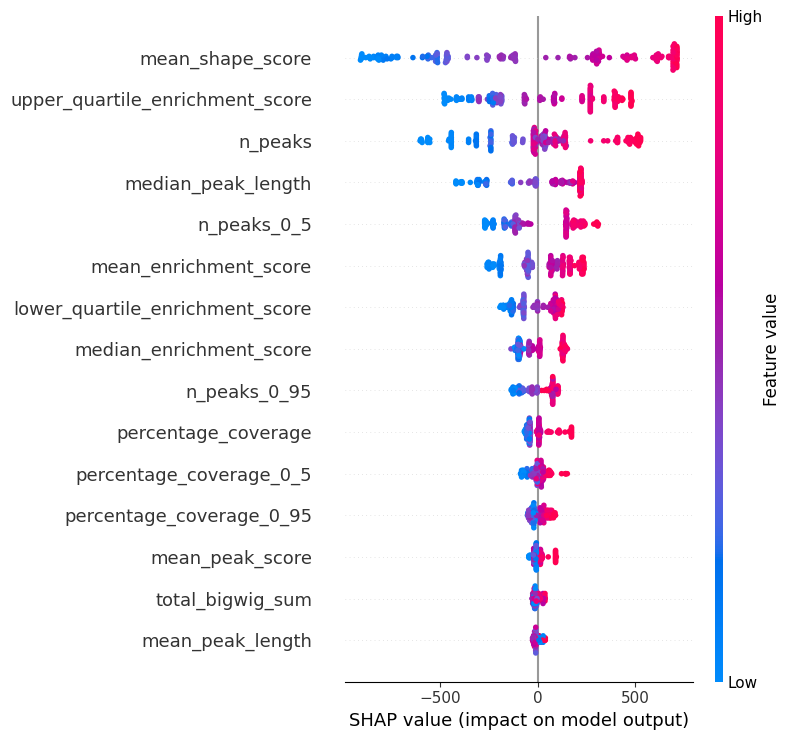

In [ ]:
import shap

X = data[list(FEATURE_COLUMNS)]
shap_values = bw_explain.compute_shap_values(result.model, X)
shap.summary_plot(shap_values, X)

## 6. Save/load the model and score a new track

`bigwig_qc.model.save_model`/`load_model` wrap XGBoost's own JSON serialisation (the format `scripts/train_model.py` writes to `results/model.json`).

In [ ]:
bw_model.save_model(result.model, "toy_model.json")
loaded = bw_model.load_model("toy_model.json")

new_track = X.iloc[[0]]
print("Predicted quality score:", loaded.predict(new_track)[0])

Predicted quality score: 3313.0945


## Where to go from here

- **Run the real pipeline on real data**: `scripts/run_features.py` -> `scripts/run_targets.py` -> `scripts/build_dataset.py` -> `scripts/train_model.py` (see the top-level README). Requires the external reference data listed in `data/README.md`.
- **The full validation suite**: each `experiments/eN_*` folder has its own README with the methodology and results for one validation experiment (degradation benchmark, cross-collection generalisation, baselines/ablations, concordance with established QC metrics, downstream utility, explainability/uncertainty, processing effects, transfer to other assays).
- **Unit tests**: `tests/` exercises every function used in this notebook (and more) against hand-constructed edge cases - run with `pytest tests/`.